# Week 1 - Day 5: Five Visualisations
HR Employee Attrition Analysis (Part 2)

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("reports/figures", exist_ok=True)

COLOR = "#1f77b4"
ACCENT = "#ff7f0e"
plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.alpha": 0.3})

df = pd.read_csv("clean_data.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,MonthlyIncome_outlier,YearsAtCompany_outlier
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,0,8,0,1,6,4,0,5,False,False
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,1,10,3,3,10,7,1,7,False,False
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,0,7,3,3,0,0,0,0,False,False
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,0,8,3,3,8,7,3,0,False,False
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,1,6,3,3,2,2,2,2,False,False


## Chart 1: Bar - Attrition Rate by Department

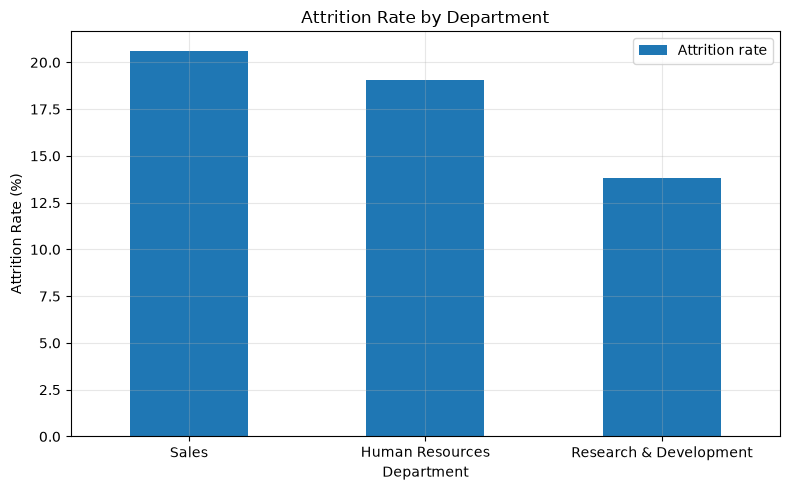

In [2]:
rate = (df["Attrition"] == "Yes").groupby(df["Department"]).mean().mul(100).sort_values(ascending=False)
ax = rate.plot(kind="bar", color=COLOR, label="Attrition rate")
ax.set_title("Attrition Rate by Department")
ax.set_xlabel("Department")
ax.set_ylabel("Attrition Rate (%)")
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("reports/figures/01_bar_attrition_dept.png", dpi=150)
plt.show()

**Insight:** Sales has the highest attrition rate at about 20.5%, followed by Human Resources at about 19%, while Research & Development is lowest at about 13.8%.

## Chart 2: Histogram - Age Distribution

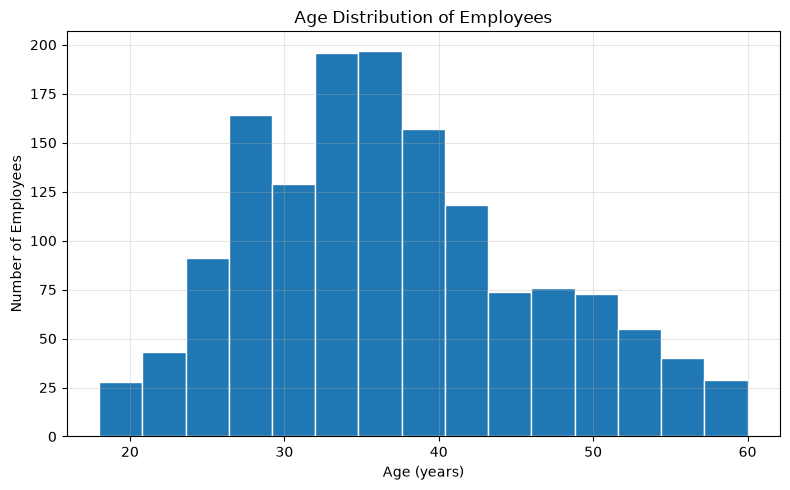

In [3]:

plt.hist(df["Age"], bins=15, color=COLOR, edgecolor="white")
plt.title("Age Distribution of Employees")
plt.xlabel("Age (years)")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.savefig("reports/figures/02_hist_age.png", dpi=150)
plt.show()

**Insight:** Most employees are between about 27 and 43 years old, with the peak at around 32 to 38 years (about 195 employees per bin). The distribution is slightly right-skewed, with fewer employees below 22 or above 55.

## Chart 3: Scatter - Monthly Income vs Total Working Years

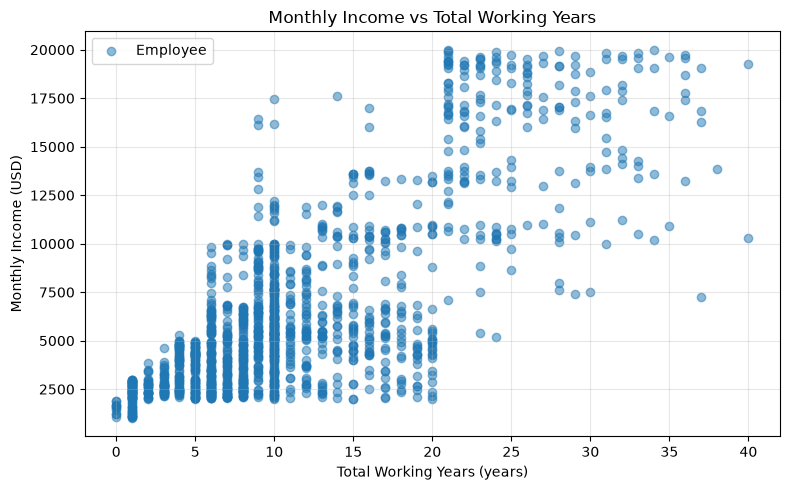

In [4]:
plt.scatter(df["TotalWorkingYears"], df["MonthlyIncome"], color=COLOR, alpha=0.5, label="Employee")
plt.title("Monthly Income vs Total Working Years")
plt.xlabel("Total Working Years (years)")
plt.ylabel("Monthly Income (USD)")
plt.legend()
plt.tight_layout()
plt.savefig("reports/figures/03_scatter_income_years.png", dpi=150)
plt.show()

**Insight:** Monthly income generally rises with total working years. Most employees with under 10 years of experience earn below about 10,000, while those with 20+ years earn between about 7,500 and 20,000, so pay varies widely at higher experience.

## Chart 4: Line - Average Monthly Income by Years at Company

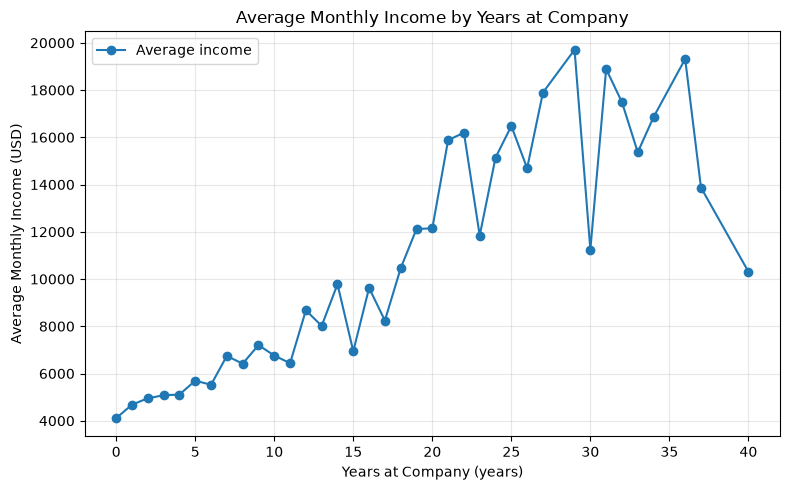

In [5]:
trend = df.groupby("YearsAtCompany")["MonthlyIncome"].mean()
plt.plot(trend.index, trend.values, marker="o", color=COLOR, label="Average income")
plt.title("Average Monthly Income by Years at Company")
plt.xlabel("Years at Company (years)")
plt.ylabel("Average Monthly Income (USD)")
plt.legend()
plt.tight_layout()
plt.savefig("reports/figures/04_line_income_tenure.png", dpi=150)
plt.show()

**Insight:** Average monthly income rises with tenure, from about 4,100 for new joiners to a peak of about 19,700 at 29 years. After about 20 years the line fluctuates sharply, and it falls to about 10,300 at 40 years.


## Chart 5: Box Plot - Monthly Income by Job Level

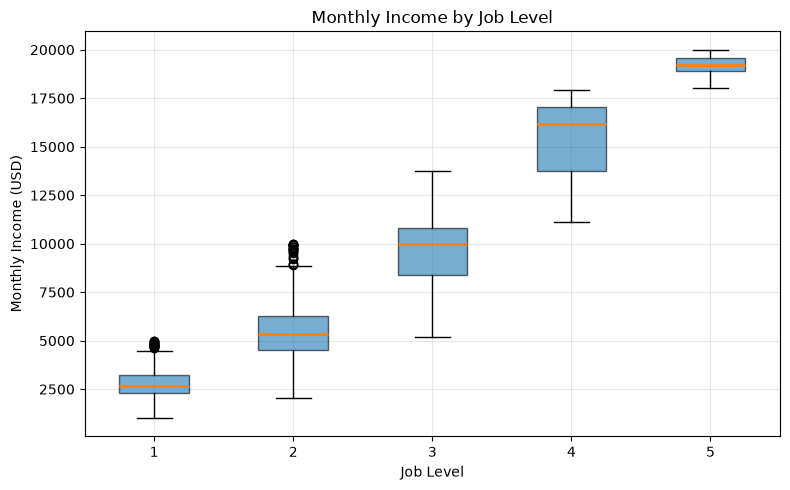

In [6]:
levels = sorted(df["JobLevel"].unique())
data = [df.loc[df["JobLevel"] == l, "MonthlyIncome"] for l in levels]
plt.boxplot(data, tick_labels=levels, patch_artist=True,
            boxprops=dict(facecolor=COLOR, alpha=0.6),
            medianprops=dict(color=ACCENT, linewidth=2))
plt.title("Monthly Income by Job Level")
plt.xlabel("Job Level")
plt.ylabel("Monthly Income (USD)")
plt.tight_layout()
plt.savefig("reports/figures/05_box_income_joblevel.png", dpi=150)
plt.show()

**Insight:** Monthly income rises steadily with job level, from a median of about 2,700 at level 1 to about 19,200 at level 5. Levels 1 and 2 show a few high outliers, and level 5 has the narrowest spread.